### Langchain Version V1

### Agents

In [2]:
import langchain

langchain.__version__

'1.5.2'

In [3]:
import os

from dotenv import load_dotenv

load_dotenv()

os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")

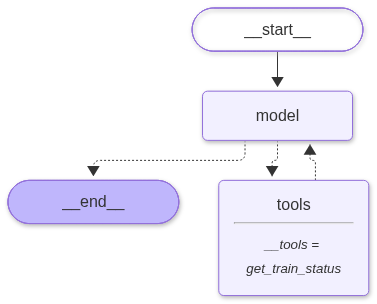

In [4]:
from langchain.agents import create_agent

TRAIN_STATUS = {
    "12951": "Mumbai Rajdhani Express is running on time.",
    "12301": "Howrah Rajdhani Express is delayed by 20 minutes.",
}

def get_train_status(train_number:str)-> str:
    """Get the current status for a train number."""
    if train_number not in TRAIN_STATUS:
        return f"No status found for train number {train_number}."
    return TRAIN_STATUS[train_number]

agent=create_agent(
    model="groq:openai/gpt-oss-20b", # openai/gpt-oss-20b
    tools=[get_train_status],
    system_prompt="You are a helpful assistant."
)
agent

In [5]:
### run the agent
response=agent.invoke({"messages":[{"role":"user","content":"What is the status of train number 12951?"}]})

In [6]:
response["messages"][-1].content

'**Train 12951 (Mumbai Rajdhani Express)**  \n- Status: Running on time.'

In [7]:
agent.invoke({"messages":"What is the status of train number 99999"})

{'messages': [HumanMessage(content='What is the status of train number 99999', additional_kwargs={}, response_metadata={}, id='01a16673-1f4f-4013-bbd2-67044bb8970b'),
  AIMessage(content='', additional_kwargs={'reasoning_content': 'We need to call the function get_train_status with train_number "99999".', 'tool_calls': [{'id': 'fc_07e50b94-8407-4582-aa1c-30b23856ebb8', 'function': {'arguments': '{"train_number":"99999"}', 'name': 'get_train_status'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 43, 'prompt_tokens': 143, 'total_tokens': 186, 'completion_time': 0.043683334, 'completion_tokens_details': {'reasoning_tokens': 17}, 'prompt_time': 0.009533261, 'prompt_tokens_details': None, 'queue_time': 0.315696805, 'total_time': 0.053216595}, 'model_name': 'openai/gpt-oss-20b', 'system_fingerprint': 'fp_e189667b30', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a22159-f269-7082-bc6d-8e

In [8]:
agent.invoke({"messages":"What was my last question?"})

{'messages': [HumanMessage(content='What was my last question?', additional_kwargs={}, response_metadata={}, id='25de9be3-6664-46cf-829d-67d97437a328'),
  AIMessage(content='Your last question was: **“What was my last question?”**', additional_kwargs={'reasoning_content': 'The user asks: "What was my last question?" They want the assistant to recall the last question the user asked. The last question was: "What was my last question?" Actually, that is the current question. The user wants the assistant to recall the last question they asked before this. The previous user message before this was: "What was my last question?" Wait, let\'s check conversation:\n\nSystem: "You are ChatGPT..."\nDeveloper: "You are a helpful assistant."\nUser: "What was my last question?"\nAssistant: This is the first assistant message. The user is asking about their last question. The last question they asked was "What was my last question?" Actually, that is the current question. But maybe they mean the last

### 🤔 Before you move on
The agent above only ever talked through `create_agent(...)` — you never touched the plain model underneath it. What if you don't want a full agent yet, just the model itself, so you can invoke it directly, stream its output, or run several prompts at once? That's exactly what `2-modelintegration.ipynb` covers next.